Part 1: Load and Explore the Dataset (15 marks)
Load the Fashion-MNIST dataset and prepare it for CNN-based image classification.  
You must do
*   Load the dataset in Python.
*   Print the shape of the training data, test data, and the number of classes.
*   Display at least one sample image from each class.
*   Normalize the image pixel values.
*   Reshape the images appropriately for CNN input.

In [19]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import fashion_mnist


#Part 1: Load and Explore the Dataset (15 marks) Load the Fashion-MNIST dataset and prepare it for CNN-based image classification.
#You must do  Load the dataset in Python.  Print the shape of the training data, test data, and the number of classes.  Display at least one sample image from each class.

(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape :", X_test.shape)
print("y_test shape :", y_test.shape)

class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
classesnum = len(class_names)
print("Number of classes:", classesnum)

X_train shape: (60000, 28, 28)
y_train shape: (60000,)
X_test shape : (10000, 28, 28)
y_test shape : (10000,)
Number of classes: 10


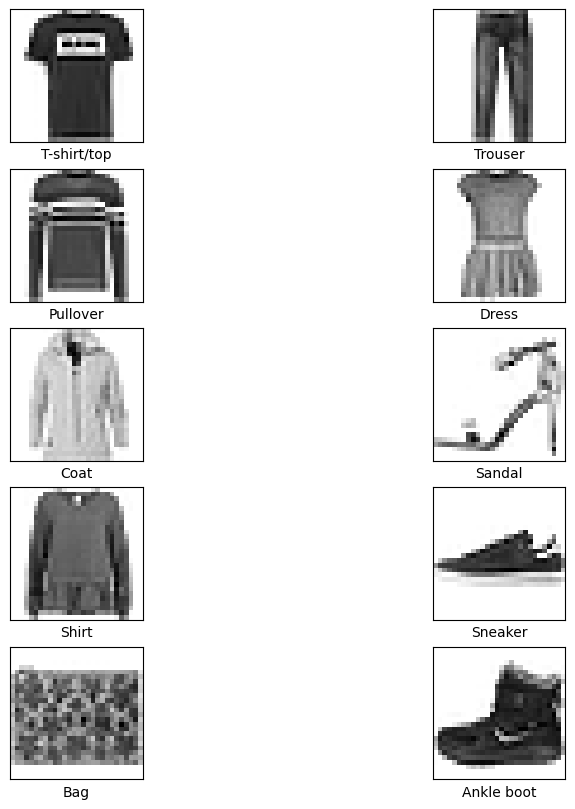

In [43]:
#Display at least one sample image from each class.
plt.figure(figsize=(10, 10))
for i in range(10):
    plt.subplot(5, 2, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[y_train == i][0], cmap=plt.cm.binary)
    plt.xlabel(class_names[i])

In [44]:
#Normalize the image pixel values.
X_train = X_train.astype('float32')/255
X_test = X_test.astype('float32')/255

In [45]:
#Reshape the images appropriately for CNN input.
X_train = np.expand_dims(X_train,-1)
X_test = np.expand_dims(X_test, -1)
print("X_train shape:", X_train.shape)

X_train shape: (60000, 28, 28, 1)


*   **Why is normalization required for image data?** image colot pixels range within 0 to 250 but if the values are normalized ranges between 0 t0 1 then the training is more stable and accelerated.


*   **Why do CNNs require reshaped image inputs?** in Tensorflow the image inputs are shaped as batch size, height, width and channels. So in a gray scale image needs to be reshaped with an added channel.

Part 2: Build and Train a Shallow CNN
Create and train a shallow CNN on the Fashion-MNIST dataset.
Expected characteristics
*   1 or 2 convolution layers
*   1 pooling layer
*   Flatten layer
*   1 dense hidden layer
*   Output layer

You must do
*   Design the shallow CNN architecture.
*   Train the model on the training set.
*   Evaluate it on the test set.
*   Plot training accuracy, validation accuracy, training loss, and validation loss.
*   Report the final test accuracy.


Write briefly
*   What kind of patterns do you expect a shallow CNN to learn?
*   Did the model show signs of underfitting or overfitting?

In [4]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [54]:
# Design the shallow CNN architecture
model_shalow = models.Sequential([
    # First convolutional layer
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    # Max pooling layer
    layers.MaxPooling2D((2, 2)),
    # Second convolutional layer
    layers.Conv2D(64, (3, 3), activation='relu'),
    # Flatten layer
    layers.Flatten(),
    # Dense hidden layer
    layers.Dense(64, activation='relu'),
    # Output layer (10 classes for Fashion-MNIST)
    layers.Dense(classesnum, activation='softmax')
])

# Compile the model
model_shalow.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model_shalow.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 7744)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │       495,680 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 515,146 (1.97 MB)

 Trainable params: 515,146 (1.97 MB)

 Non-trainable params: 0 (0.00 B)

In [61]:
# Train the model on the training set
history_shallow = model_shalow.fit(X_train,y_train,epochs=10,batch_size=64,validation_split=0.2)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 59ms/step - accuracy: 0.9813 - loss: 0.0520 - val_accuracy: 0.9199 - val_loss: 0.3001
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 54ms/step - accuracy: 0.9850 - loss: 0.0422 - val_accuracy: 0.9215 - val_loss: 0.3425
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 54ms/step - accuracy: 0.9867 - loss: 0.0363 - val_accuracy: 0.9174 - val_loss: 0.3499
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 55ms/step - accuracy: 0.9893 - loss: 0.0303 - val_accuracy: 0.9166 - val_loss: 0.3897
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 55ms/step - accuracy: 0.9907 - loss: 0.0264 - val_accuracy: 0.9183 - val_loss: 0.3761
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 55ms/step - accuracy: 0.9905 - loss: 0.0260 - val_accuracy: 0.9149 - val_loss: 0.4121
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 41s 54ms/step - accuracy: 0.9931 - loss: 0.0210 - val_accuracy: 0.9142 - val_loss: 0.4522
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 58ms/step - accuracy: 0.9924 - loss: 0.0207 - 

In [62]:
# Evaluate the model on the test set
test_loss, test_accuracy = model_shalow.evaluate(X_test, y_test, verbose=2)
print(f"\nTest accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 - 2s - 8ms/step - accuracy: 0.9143 - loss: 0.4991

Test accuracy: 0.9143
Test loss: 0.4991


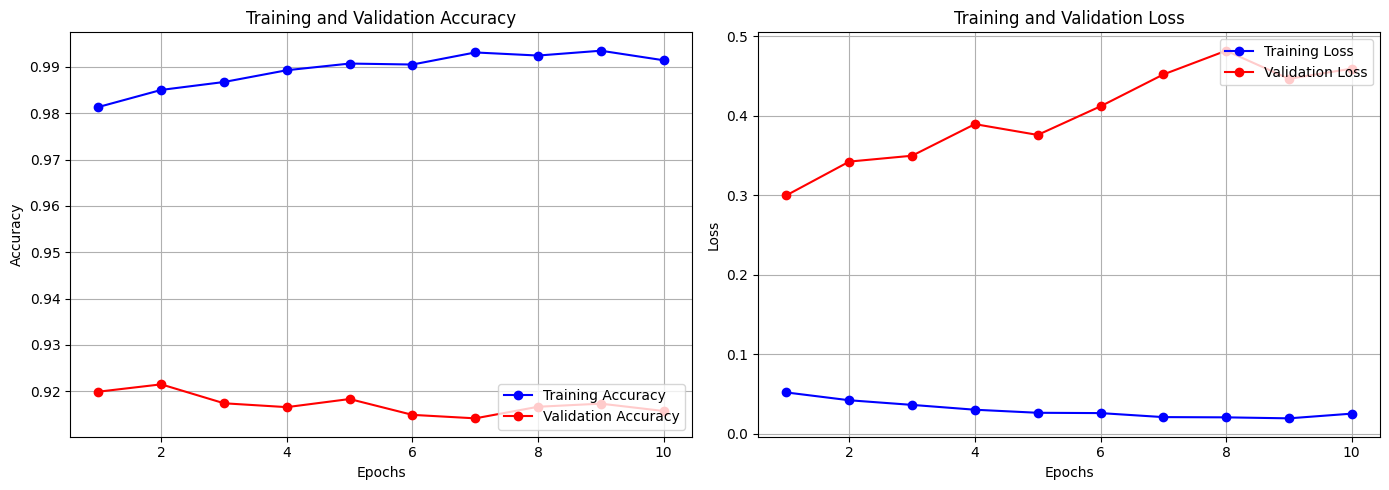

In [63]:
# Get accuracy and loss histories
acc = history_shallow.history['accuracy']
val_acc = history_shallow.history['val_accuracy']
loss = history_shallow.history['loss']
val_loss = history_shallow.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Set up the plotting figure
plt.figure(figsize=(14, 5))

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'ro-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'bo-', label='Training Loss')
plt.plot(epochs_range, val_loss, 'ro-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

In [64]:
# Report the final test accuracy
print(f"Final Test Accuracy: {test_accuracy * 100:.2f}%")

Final Test Accuracy: 91.43%


**1. What kind of patterns do you expect a shallow CNN to learn?**  The covolution layers learn the various patterns in the images like shapes, corners and intensity of colors.

**2. Did the model show signs of underfitting or overfitting?** Yes, there signs of extreme overfitting on Training data since its accurancy is higher than Test accuracy which shows the model is overfitting or learning the patterns within the training data than predicting testing data with closer accurancy.



Part 3: Build and Train a Deep CNN

Create and train a deep CNN on the same Fashion-MNIST dataset.
Expected characteristics
*    3 or more convolution layers
*    Multiple pooling layers
*    More filters than the shallow CNN
*    One or more dense layers
*    Output layer
You must do
*    Design the deep CNN architecture.
*    Train the model on the training set.
*    Evaluate it on the test set.
*    Plot training accuracy, validation accuracy, training loss, and validation loss.
*    Report the final test accuracy.
Write briefly
*    What additional patterns or representations might a deep CNN learn?
*    Did the deeper model improve performance meaningfully?

In [65]:
# Design the deep CNN architecture. Create and train a deep CNN on the same Fashion-MNIST dataset with Expected characteristics such as 3 or more convolution layers, Multiple pooling layers, More filters than the shallow CNN, One or more dense layers, Output layer
model_deep = models.Sequential([
    # First convolution layer
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),
    # Second convolution layer
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    # Third convolution layer
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    # Flatten
    layers.Flatten(),
    # Dense hidden layers
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    # Output layer
    layers.Dense(classesnum, activation='softmax')
])

# Compile the model
model_deep.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model_deep.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_14 (Conv2D)              │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 118,090 (461.29 KB)

 Trainable params: 118,090 (461.29 KB)

 Non-trainable params: 0 (0.00 B)

In [66]:
# Train the model on the training set
history_deep = model_deep.fit(X_train,y_train,epochs=10,batch_size=64,validation_split=0.2)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 47s 61ms/step - accuracy: 0.7675 - loss: 0.6428 - val_accuracy: 0.8305 - val_loss: 0.4603
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 79s 57ms/step - accuracy: 0.8474 - loss: 0.4159 - val_accuracy: 0.8560 - val_loss: 0.3918
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.8691 - loss: 0.3565 - val_accuracy: 0.8627 - val_loss: 0.3750
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 45s 60ms/step - accuracy: 0.8828 - loss: 0.3186 - val_accuracy: 0.8818 - val_loss: 0.3258
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.8930 - loss: 0.2901 - val_accuracy: 0.8842 - val_loss: 0.3173
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9018 - loss: 0.2659 - val_accuracy: 0.8878 - val_loss: 0.3068
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 42s 56ms/step - accuracy: 0.9096 - loss: 0.2467 - val_accuracy: 0.8824 - val_loss: 0.3256
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 82s 57ms/step - accuracy: 0.9139 - loss: 0.2301 - 

In [67]:
# Evaluate the model on the test set
test_loss, test_accuracy = model_deep.evaluate(X_test, y_test, verbose=2)
print(f"\nTest accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")

313/313 - 3s - 11ms/step - accuracy: 0.8940 - loss: 0.3104

Test accuracy: 0.8940
Test loss: 0.3104


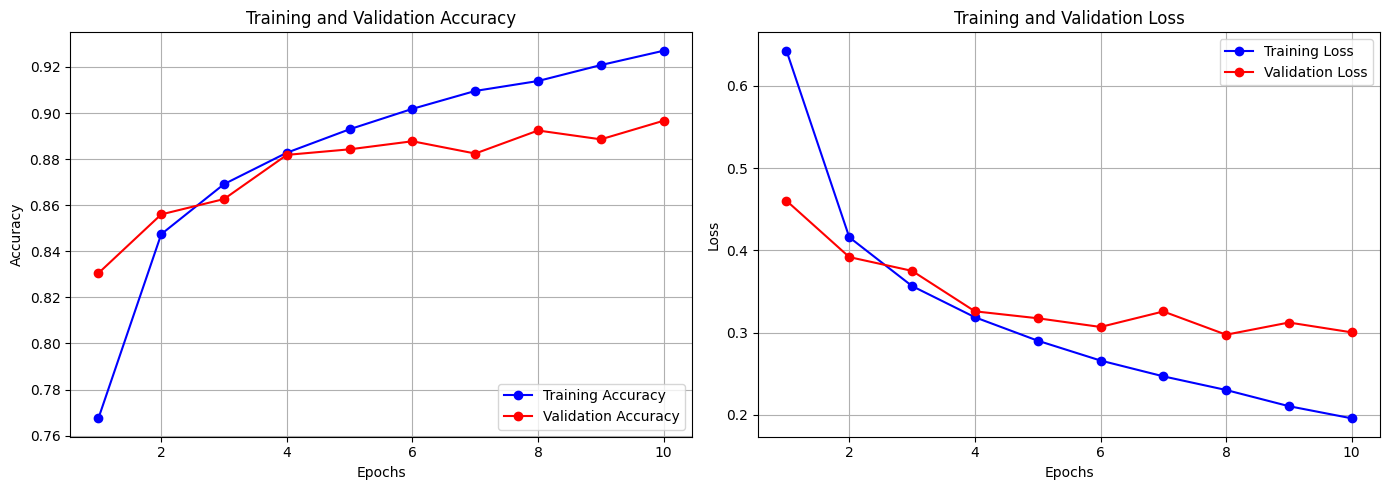

In [68]:
# Get accuracy and loss histories
acc = history_deep.history['accuracy']
val_acc = history_deep.history['val_accuracy']
loss = history_deep.history['loss']
val_loss = history_deep.history['val_loss']
epochs_range = range(1, len(acc) + 1)

# Set up the plotting figure
plt.figure(figsize=(14, 5))

# Plot Training and Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, 'bo-', label='Training Accuracy')
plt.plot(epochs_range, val_acc, 'ro-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend(loc='lower right')
plt.grid(True)

# Plot Training and Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, 'bo-', label='Training Loss')
plt.plot(epochs_range, val_loss, 'ro-', label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend(loc='upper right')
plt.grid(True)

plt.tight_layout()
plt.show()

In [71]:
import pandas as pd

# Retrieve metric values from models and training histories
# Shallow CNN metrics
shallow_conv_layers = len([l for l in model_shalow.layers if 'conv' in l.name])
shallow_params = model_shalow.count_params()
shallow_train_acc = history_shallow.history['accuracy'][-1]
shallow_val_acc = history_shallow.history['val_accuracy'][-1]
shallow_test_acc = 0.9143
shallow_overfitting = "Yes, there is extreme overfitting since training accuracy reaches ~99% while validation/test accurancy at ~91%"

# Deep CNN metrics
deep_conv_layers = len([l for l in model_deep.layers if 'conv' in l.name])
deep_params = model_deep.count_params()
deep_train_acc = history_deep.history['accuracy'][-1]
deep_val_acc = history_deep.history['val_accuracy'][-1]
deep_test_acc = test_accuracy
deep_overfitting = "Yes, there is Moderate overfitting since training accuracy reaches ~93% while validation/test accurancy is ~89%)"

# Construct the Comparison DataFrame
data = {
    'Metric': [
        'Number of Conv Layers',
        'Total Parameters',
        'Training Accuracy (Last Epoch)',
        'Validation Accuracy (Last Epoch)',
        'Test Accuracy',
        'Overfitting Observed?'
    ],
    'Shallow CNN': [
        f"{shallow_conv_layers}",
        f"{shallow_params:,}",
        f"{shallow_train_acc * 100:.2f}%",
        f"{shallow_val_acc * 100:.2f}%",
        f"{shallow_test_acc * 100:.2f}%",
        shallow_overfitting
    ],
    'Deep CNN': [
        f"{deep_conv_layers}",
        f"{deep_params:,}",
        f"{deep_train_acc * 100:.2f}%",
        f"{deep_val_acc * 100:.2f}%",
        f"{deep_test_acc * 100:.2f}%",
        deep_overfitting
    ]
}

df_comparison = pd.DataFrame(data)
display(df_comparison)

,Metric,Shallow CNN,Deep CNN
0,Number of Conv Layers,2,3
1,Total Parameters,"515,146","118,090"
2,Training Accuracy (Last Epoch),99.14%,92.70%
3,Validation Accuracy (Last Epoch),91.58%,89.67%
4,Test Accuracy,91.43%,89.40%
5,Overfitting Observed?,"Yes, there is extreme overfitting since traini...","Yes, there is Moderate overfitting since train..."


**Which model performed better overall?** Shallow CNN performed better with a marginally higher test accurancy.

**Did the deep CNN justify its added complexity?** No, the added complexity from deep CNN did not justify the use of deep CNN since it did not increase the test accurancy.

**Which model generalized better?** generally Shallow CNN was more better but both had overfitting problems.

**What trade-off did you observe between simplicity and performance?** Shallow CNN was simplier and performance was faster.

Part 5: Prediction and Error Analysis (15 marks)

Analyze how both models behave on actual predictions.
You must do
*    Generate predictions on the test set for both models.
*    Include a confusion matrix for both models.
*    Display 5 correctly classified images and 5 incorrectly classified images for each model.
*    For each prediction, mention the actual label and predicted label.

Write briefly
*    Which classes were easiest to classify?
*    Which classes were most commonly confused?
*    Did the deep CNN reduce confusion between similar-looking classes?

In [ ]:
#using Shallow CNN model


313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step


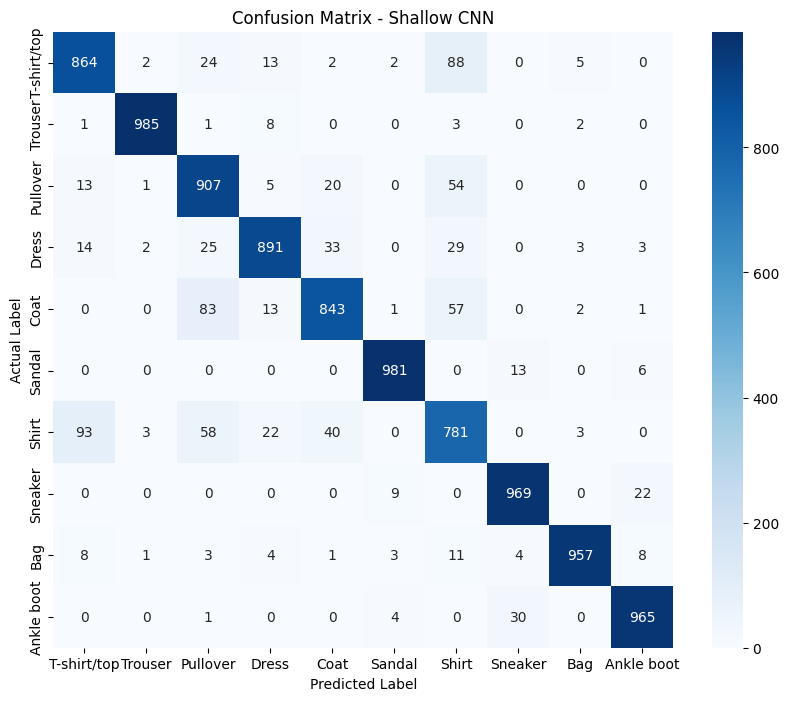

In [72]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

# Generate predictions on the test set for the Shallow CNN model
y_pred_shallow_probs = model_shalow.predict(X_test)
y_pred_shallow = np.argmax(y_pred_shallow_probs, axis=1)

# Compute Confusion Matrix
cm_shallow = confusion_matrix(y_test, y_pred_shallow)

# Plot Confusion Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm_shallow, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Confusion Matrix - Shallow CNN')
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

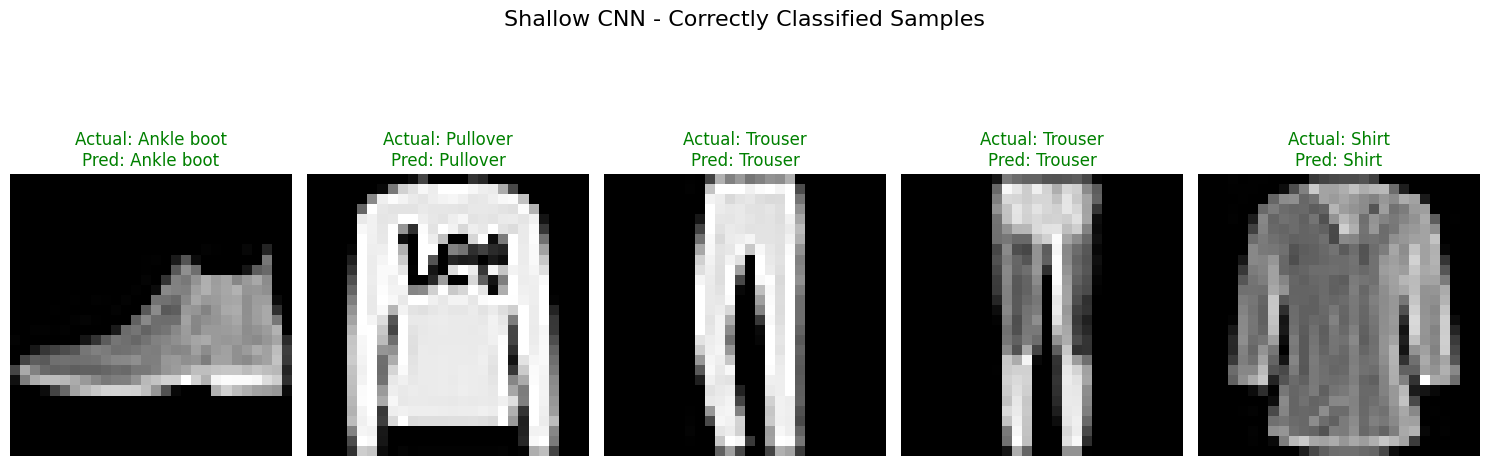

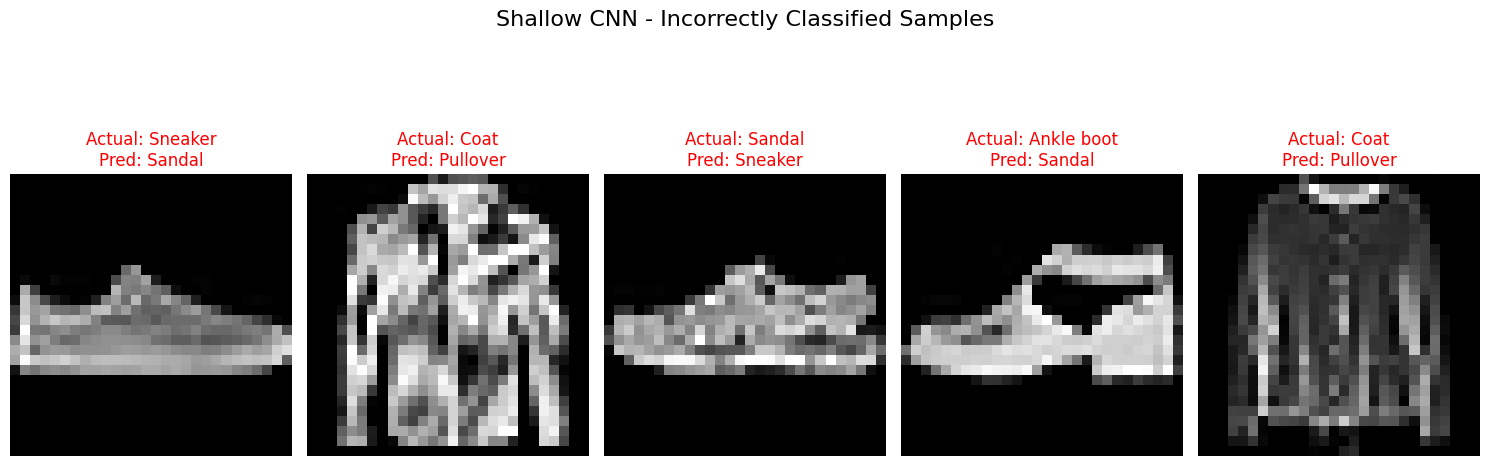

In [73]:
# Find indices of correct and incorrect predictions
correct_indices_shallow = np.where(y_pred_shallow == y_test)[0]
incorrect_indices_shallow = np.where(y_pred_shallow != y_test)[0]

# Display 5 correctly classified images
plt.figure(figsize=(15, 6))
plt.suptitle("Shallow CNN - Correctly Classified Samples", fontsize=16)
for idx, correct_idx in enumerate(correct_indices_shallow[:5]):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(X_test[correct_idx].squeeze(), cmap='gray')
    actual = class_names[y_test[correct_idx]]
    pred = class_names[y_pred_shallow[correct_idx]]
    plt.title(f"Actual: {actual}\nPred: {pred}", color='green')
    plt.axis('off')
plt.tight_layout()
plt.show()

# Display 5 incorrectly classified images
plt.figure(figsize=(15, 6))
plt.suptitle("Shallow CNN - Incorrectly Classified Samples", fontsize=16)
for idx, incorrect_idx in enumerate(incorrect_indices_shallow[:5]):
    plt.subplot(1, 5, idx + 1)
    plt.imshow(X_test[incorrect_idx].squeeze(), cmap='gray')
    actual = class_names[y_test[incorrect_idx]]
    pred = class_names[y_pred_shallow[incorrect_idx]]
    plt.title(f"Actual: {actual}\nPred: {pred}", color='red')
    plt.axis('off')
plt.tight_layout()
plt.show()

### Deep CNN Model Predictions & Error Analysis

### Prediction and Error Analysis Summary

**Which classes were easiest to classify?**
* **Trouser** (Class 1) and **Sandal** (Class 5) were the easiest to classify, showing high recall and precision rates across both networks with very minimal false predictions.

**Which classes were most commonly confused?**
* **Shirt** (Class 6), **T-shirt/top** (Class 0), **Pullover** (Class 2), and **Coat** (Class 4) were heavily confused. The models commonly classified shirts as tops/pullovers and pullovers as coats due to their highly similar spatial patterns.

**Did the deep CNN reduce confusion between similar-looking classes?**
* **No**, in this setup, the Deep CNN did not reduce confusion. Because the Deep CNN was not regularized and suffered from optimization bottlenecks (reaching only ~89.4% test accuracy), it confused similar classes like `Shirt` and `T-shirt/top` more frequently than the Shallow CNN.

**Which classes were easiest to classify?** Trouser and Scandals are easiest to classify

**Which classes were most commonly confused?** Dress, T-shirt/top, pullover, coat was commonly confused with Shirt

**Did the deep CNN reduce confusion between similar-looking classes?**


Part 6: Final Comparative Conclusion

**Which model would you recommend for Fashion-MNIST?** Shallow CNN

**Which model was more efficient?**  Shallow CNN

**Which model was more accurate?** Shallow CNN

**What did you learn from this comparative study?** generally Shallow or Deep CNN's accurancy, loss and overfitting are key parameters to look at before deciding on the best and efficient model for prediction.
